# Livrable 3, partie 1 : le modèle entrainé par notre groupe (CNN + attention + GRU)

Groupe :
* Isrâ BOUDEMAGH
* Théophile NOEL
* Bruno RIECKENBERG
* Corentin ROMANO

## Objectif

Dernière étape du workflow TouNum : pour chaque **photo** gardée par le livrable 1 et nettoyée par le livrable 2, produire
**une phrase qui décrit l'image** (« a man riding a horse on a beach »). C'est l'**image captioning** : un réseau qui lit
une image et écrit une phrase, mot par mot.

```
 images numérisées ──► [ L2 : débruitage ] ──► [ L1 : photo, peinture ou autre ? ] ──► [ L3 : captioning ]
                        toutes les images         on ne garde que les photos              (ce livrable)
```

## Démarche : deux notebooks

Le livrable 3 part des deux workshops du bloc (**Transfer Learning** puis **Annotation d'images**) et les mène jusqu'au
bout, avec une évaluation honnête. Il est découpé en deux notebooks indépendants, chacun lancé dans son propre noyau :

| Notebook | Contenu | Bibliothèque |
|---|---|---|
| **`L3_1_modele_workshops.ipynb`** (celui-ci) | parties 1 à 7 : on reconstruit et on entraîne le modèle des workshops, un **CNN pré-entraîné** (transfer learning) qui résume l'image en 49 régions, un **mécanisme d'attention** et un **décodeur GRU** entraîné de zéro sur MS COCO ; on le mesure sur des images qu'il n'a jamais vues : **il ne fonctionne pas correctement**, et on explique pourquoi | TensorFlow / Keras |
| `L3_2_BLIP.ipynb` | parties 8 à 10 : on le remplace par **BLIP**, un modèle vision-langage pré-entraîné de Salesforce, que l'on compare au premier sur les mêmes images, puis que l'on **enregistre dans `models/`** : c'est lui qu'utilisent le site de test et la pipeline | PyTorch / Transformers |

Les deux bibliothèques ne sont jamais chargées dans le même noyau : chacune garde toute la mémoire (vive et carte
graphique) pour elle. Ce notebook enregistre le modèle 1 et ses résultats dans `models/` ; le second les relit pour la
comparaison. **Lancer donc celui-ci en premier.**

## Plan de ce notebook

| Partie | Contenu |
|---|---|
| 1 | **Données** : MS COCO 2014, légendes, sous-ensemble, statistiques |
| 2 | **Transfer learning** : extraction des caractéristiques avec EfficientNetB0 pré-entraîné, et preuve qu'elles ont du sens (t-SNE, sonde linéaire) |
| 3 | **Prétraitement du texte** : vocabulaire, jetons, découpage entraînement / validation / test |
| 4 | **Modèle 1 : encodeur CNN + attention de Bahdanau + décodeur GRU** (code et fonctionnement) |
| 5 | **Entraînement** : perte masquée, Adam, early stopping, enregistrement |
| 6 | **Évaluation du modèle 1** : légendes, attention, BLEU, diversité, images du projet ; résultats enregistrés pour la partie 2 |
| 7 | **Diagnostic : pourquoi le modèle 1 ne fonctionne pas** |

Le notebook se lance seul depuis le dossier `Livrable3/` : il lit les données, entraîne le modèle 1, **l'enregistre dans
`models/` dès la fin de l'entraînement**, puis l'évalue.

> **Chiffres cités dans le texte.** Ils viennent d'une exécution de bout en bout sur une machine **sans carte
> graphique** (processeur 2 cœurs) : les temps (entraînement, ms par image) y sont bien plus longs qu'avec la carte
> graphique, et les scores varient un peu d'un entraînement à l'autre.

In [1]:
# Bibliothèques : TensorFlow / Keras pour le modèle des workshops (BLIP, en PyTorch, est dans L3_2_BLIP.ipynb),
# NumPy / Pandas pour les calculs et tableaux, Matplotlib pour les figures, scikit-learn pour le t-SNE
import collections
import json
import math
import os
import pathlib
import random
import time

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
# Utiliser le GPU lorsqu'il est disponible ; définir L3_USE_GPU=0 pour forcer le CPU.
UTILISER_GPU = os.environ.get("L3_USE_GPU", "1") == "1"

import gc
import sys
import ctypes
import faulthandler

# Si le noyau s'arrête net (erreur de mémoire du code C, bibliothèque CUDA...), Python écrit au moins la ligne en cause
# dans le journal du noyau (VS Code : panneau Sortie > Jupyter) au lieu d'un simple « Kernel crashed ».
faulthandler.enable(file=sys.__stderr__)


# ----- Mémoire (Linux / WSL) -----
# Sur processeur, TensorFlow calcule avec beaucoup de fils d'exécution ; la bibliothèque C de Linux donne à chacun sa
# propre réserve de mémoire (jusqu'à 8 par cœur) et rend rarement au système ce qui a été libéré. Sur un long
# notebook, la mémoire occupée grossit alors de plusieurs Go jusqu'à ce que WSL arrête le noyau (« Kernel crashed »).
# On limite donc ces réserves à 2 AVANT d'importer TensorFlow, et liberer_memoire() rend au système la mémoire libérée.
_LIBC = None
if sys.platform.startswith("linux"):
    try:
        _LIBC = ctypes.CDLL("libc.so.6")
        _LIBC.mallopt(-8, 2)          # M_ARENA_MAX = 2
    except OSError:
        _LIBC = None


def memoire_utilisee():
    "Mémoire vive occupée par ce noyau, en Mo (None si on ne sait pas la lire)."
    try:
        with open("/proc/self/status") as f:
            return next(int(l.split()[1]) // 1024 for l in f if l.startswith("VmRSS"))
    except (OSError, StopIteration):
        return None


def liberer_memoire(etape=""):
    "Ramasse-miettes Python, puis rend au système la mémoire libérée (Linux). Affiche la mémoire occupée."
    gc.collect()
    if _LIBC is not None:
        _LIBC.malloc_trim(0)
    m = memoire_utilisee()
    if m is not None:
        print(f"Mémoire occupée par le noyau{' ' + etape if etape else ''} : {m / 1024:.1f} Go")


# ----- Bibliothèques CUDA de TensorFlow (Linux / WSL) -----
# TensorFlow 2.21 trouve seul les bibliothèques nvidia-*-cu12 installées avec lui, sauf libcusolver.so.11 : sans elle, il
# abandonne la carte graphique (« Cannot dlopen some GPU libraries », GPU détectés : []). Le noyau « Leyenda » corrige
# cela par LD_LIBRARY_PATH, mais VS Code n'applique pas toujours les variables d'un noyau. On charge donc nous-mêmes
# cuSOLVER et les bibliothèques dont elle dépend AVANT d'importer TensorFlow : il la retrouve alors déjà chargée.
def precharger_cuda():
    try:
        import nvidia                    # dossier site-packages/nvidia/ des paquets nvidia-*-cu12
    except ImportError:
        return
    for sous_dossier, fichier in (("nvjitlink", "libnvJitLink.so.12"), ("cublas", "libcublasLt.so.12"),
                                  ("cublas", "libcublas.so.12"), ("cusparse", "libcusparse.so.12"),
                                  ("cusolver", "libcusolver.so.11")):
        for racine in nvidia.__path__:
            chemin = pathlib.Path(racine) / sous_dossier / "lib" / fichier
            if chemin.is_file():
                try:
                    ctypes.CDLL(str(chemin), mode=ctypes.RTLD_GLOBAL)
                except OSError as e:
                    print("Chargement impossible :", e)
                break


if UTILISER_GPU and sys.platform.startswith("linux"):
    precharger_cuda()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image

# TensorFlow réserve par défaut toute la mémoire de la carte graphique : on la fait grandir à la demande, pour
# laisser de la place aux autres programmes (le serveur du site, un autre notebook).
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

print("TensorFlow :", tf.__version__)
print("GPU détectés :", tf.config.list_physical_devices("GPU"))
if UTILISER_GPU and not tf.config.list_physical_devices("GPU"):
    print("ATTENTION : TensorFlow ne voit pas la carte graphique, tout sera calculé sur le processeur (beaucoup plus lent).\n"
          "Choisir le noyau « Leyenda (TensorFlow + PyTorch GPU) » ; s'il manque, lancer installer_environnement.sh (racine du projet).")

I0000 00:00:1792709936.081792    1039 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792709949.559042    1039 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow : 2.21.0
GPU détectés : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# ----- Paramètres du notebook, regroupés ici pour pouvoir tout relancer avec d'autres valeurs -----
# Les variables d'environnement L3_* permettent de les changer sans modifier le code (test rapide, machine sans GPU).
SEED = 42                                                  # même graine que les livrables 1 et 2
RETRAIN = os.environ.get("L3_RETRAIN", "1") == "1"         # False : recharge le modèle 1 déjà enregistré s'il existe
MAX_IMAGES = int(os.environ.get("L3_MAX_IMAGES", 5000))    # images COCO utilisées au plus (comme le workshop)
CNN = os.environ.get("L3_CNN", "efficientnet")             # "efficientnet" (workshop final) ou "inception" (workshop d'origine)

TOP_K = 5000             # taille du vocabulaire : les 5000 mots les plus fréquents (comme le workshop)
MAX_MOTS = 20            # légendes de plus de 20 mots écartées (environ 2 % des légendes, voir partie 1)
EMBEDDING = 256          # dimension des vecteurs de mots et des régions d'image après l'encodeur
UNITS = 512              # taille de l'état caché du GRU et de la couche d'attention
BATCH = 64
LR = 3e-4                # pas d'apprentissage d'Adam (valeur du workshop)
EPOCHS = int(os.environ.get("L3_EPOCHS", 30))              # nombre maximal d'époques (l'early stopping arrête avant)
PATIENCE = int(os.environ.get("L3_PATIENCE", 3))           # époques sans progrès de la validation avant l'arrêt
LARGEUR_FAISCEAU = 3     # recherche en faisceau du modèle 1 (comme le workshop)
N_EVAL = int(os.environ.get("L3_N_EVAL", 0))               # images de test évaluées (0 = tout le jeu de test)

# Emplacements. Les données COCO sont cherchées dans l'ordre : variable L3_COCO, dossier courant, dataset/, workshop
COCO_CANDIDATS = [os.environ.get("L3_COCO", ""), ".", "./dataset", "../../workshop"]
MODELS_DIR = pathlib.Path("../models")                     # TOUS les modèles du projet
CACHE_DIR = pathlib.Path("./cache_features") / CNN         # caractéristiques d'images pré-calculées (non versionné)
TEST_PHOTOS = pathlib.Path("../Test_photos")               # 12 images du projet, jamais vues par aucun des modèles
FICHIERS_MODELE_1 = {
    "encodeur": MODELS_DIR / "l3_attention_encodeur.weights.h5",
    "decodeur": MODELS_DIR / "l3_attention_decodeur.weights.h5",
    "vocabulaire": MODELS_DIR / "l3_attention_vocabulaire.json",
    "historique": MODELS_DIR / "l3_attention_historique.csv",
    "resultats": MODELS_DIR / "l3_attention_resultats.json",   # légendes et scores, relus par L3_2_BLIP.ipynb
}

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
print(f"CNN : {CNN} · entraînement : {'oui' if RETRAIN else 'non (rechargement)'} · époques max : {EPOCHS}")

CNN : efficientnet · entraînement : oui · époques max : 30


## 1. Données : MS COCO 2014

Comme dans les workshops, on utilise **MS COCO** (*Common Objects in Context*) : des photos du quotidien, chacune décrite
par **cinq légendes** écrites par des personnes différentes. Le fichier `annotations/captions_train2014.json` contient
les 414 113 légendes des 82 783 images du jeu `train2014` ; seules les images réellement présentes sur le disque sont
utilisées (le workshop en avait téléchargé une partie).

Comme le workshop, on encadre chaque légende par deux mots spéciaux : `<start>` (le décodeur commence par lui) et
`<end>` (il s'arrête quand il le produit).

In [3]:
# Dossier COCO : le premier candidat qui contient annotations/captions_train2014.json et train2014/
def trouver_coco():
    for c in COCO_CANDIDATS:
        if c and (pathlib.Path(c) / "annotations" / "captions_train2014.json").is_file() and (pathlib.Path(c) / "train2014").is_dir():
            return pathlib.Path(c)
    raise FileNotFoundError(f"Données COCO introuvables. Emplacements testés : {[c for c in COCO_CANDIDATS if c]}")

COCO_DIR = trouver_coco()
with open(COCO_DIR / "annotations" / "captions_train2014.json", encoding="utf-8") as f:
    annotations = json.load(f)

# Regrouper les légendes par image (5 par image en général)
legendes_par_image = collections.defaultdict(list)
for a in annotations["annotations"]:
    nom = f"COCO_train2014_{a['image_id']:012d}.jpg"
    legendes_par_image[nom].append(a["caption"].strip())

# Images présentes sur le disque, triées (ordre reproductible), puis sous-ensemble de MAX_IMAGES images
presentes = {e.name for e in os.scandir(COCO_DIR / "train2014") if e.name.lower().endswith(".jpg")}
noms_images = sorted(n for n in legendes_par_image if n in presentes)[:MAX_IMAGES]
chemins_images = {n: str(COCO_DIR / "train2014" / n) for n in noms_images}
n_legendes = sum(len(legendes_par_image[n]) for n in noms_images)
print(f"Données : {COCO_DIR.resolve()}")
print(f"{len(annotations['images'])} images annotées dans le fichier, {len(presentes)} présentes sur le disque")
del annotations   # le fichier complet (414 000 légendes) n'est plus utile : on libère la mémoire
print(f"Sous-ensemble utilisé : {len(noms_images)} images, {n_legendes} légendes")

Données : /mnt/d/A5/projet/Livrable3
82783 images annotées dans le fichier, 3611 présentes sur le disque
Sous-ensemble utilisé : 3611 images, 18065 légendes


Mots par légende : moyenne 10.4, médiane 10, 95e centile 15, maximum 47
Légendes de plus de 20 mots : 0.7% (écartées de l'entraînement)


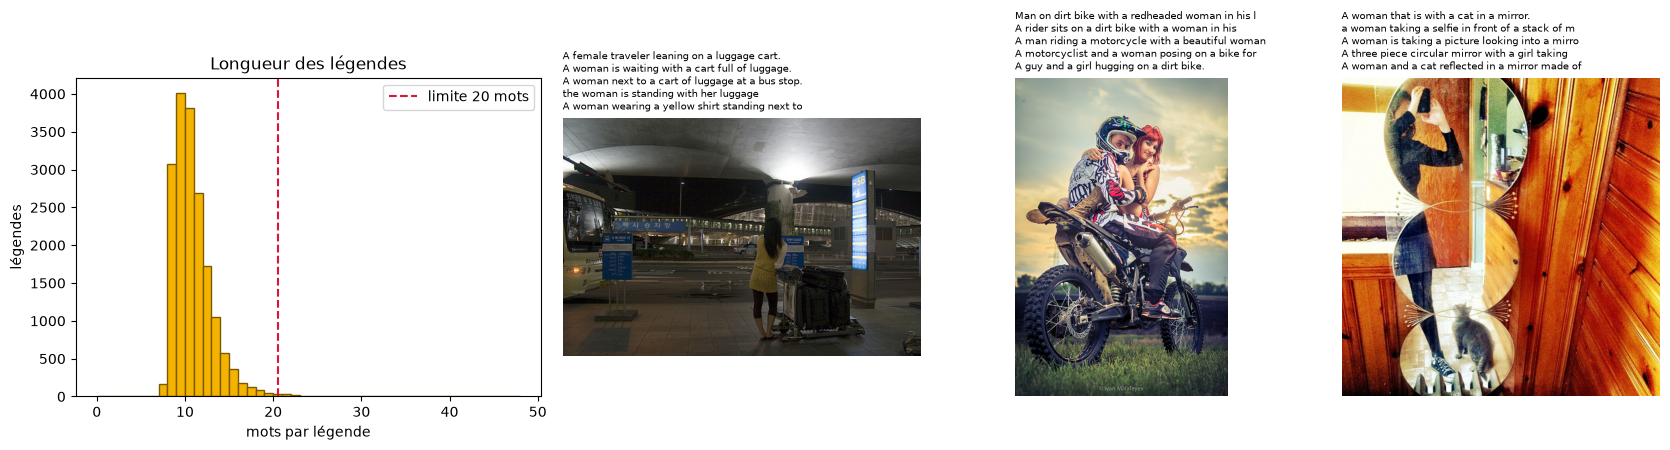

In [4]:
# Longueur des légendes, en mots
FILTRES = '!"#$%&()*+.,-/:;=?@[\\]^_`{|}~'   # ponctuation retirée, comme le Tokenizer du workshop
TABLE_FILTRES = str.maketrans({c: " " for c in FILTRES})

def mots(texte):
    "Découpe une phrase en mots : minuscules, ponctuation retirée (même règle que le Tokenizer Keras du workshop)."
    return texte.lower().translate(TABLE_FILTRES).split()

longueurs = np.array([len(mots(l)) for n in noms_images for l in legendes_par_image[n]])
print(f"Mots par légende : moyenne {longueurs.mean():.1f}, médiane {np.median(longueurs):.0f}, "
      f"95e centile {np.percentile(longueurs, 95):.0f}, maximum {longueurs.max()}")
print(f"Légendes de plus de {MAX_MOTS} mots : {np.mean(longueurs > MAX_MOTS):.1%} (écartées de l'entraînement)")

fig, axes = plt.subplots(1, 4, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.3, 1, 1, 1]})
axes[0].hist(longueurs, bins=range(0, longueurs.max() + 2), color="#f5b301", edgecolor="#7a5a00")
axes[0].axvline(MAX_MOTS + 0.5, color="crimson", ls="--", label=f"limite {MAX_MOTS} mots")
axes[0].set_xlabel("mots par légende"); axes[0].set_ylabel("légendes"); axes[0].legend(); axes[0].set_title("Longueur des légendes")
for ax, n in zip(axes[1:], noms_images[:3]):
    ax.imshow(Image.open(chemins_images[n]).convert("RGB")); ax.axis("off")
    ax.set_title("\n".join(l[:48] for l in legendes_par_image[n][:5]), fontsize=7.5, loc="left")
plt.tight_layout(); plt.show()

Les légendes sont courtes (une dizaine de mots) et décrivent la scène de façon factuelle. Les cinq légendes d'une même
image varient beaucoup : il n'y a pas **une** bonne réponse, ce qui compte pour l'évaluation (partie 6).

Le workshop complétait toutes les légendes jusqu'à la plus longue (près de 50 mots) : le GRU était alors déroulé sur
50 pas pour chaque lot, alors que 95 % des légendes en ont moins de 17. Écarter les rares légendes de plus de 20 mots
divise le temps d'entraînement par plus de deux sans rien changer à ce que le modèle apprend.

## 2. Transfer learning : un CNN pré-entraîné résume l'image

### Principe (workshop Transfer Learning)

Apprendre à « voir » demande des millions d'images. Le **transfer learning** réutilise un réseau convolutif déjà
entraîné sur **ImageNet** (1,2 million d'images, 1000 classes) : ses premières couches détectent des contours et des
textures, les suivantes des motifs, puis des parties d'objets. Ces **caractéristiques** sont utiles bien au-delà des 1000
classes d'origine.

* `include_top=False` retire la **tête de classification** (pooling global + couche dense à 1000 sorties) : on garde la
  dernière carte de caractéristiques convolutive, qui décrit encore **où** se trouve chaque chose dans l'image.
* Le CNN est **gelé** (`trainable = False`) : ses poids ne changent pas. On calcule donc ses sorties **une seule fois**
  pour toutes les images et on les met en cache sur le disque : l'entraînement du décodeur devient bien plus rapide.

### EfficientNetB0 plutôt qu'InceptionV3

Le workshop d'origine utilisait **InceptionV3** (images 299×299, carte 8×8×2048 = 64 régions de 2048 valeurs). La
version finale du workshop est passée à **EfficientNetB0** (images 224×224, carte 7×7×1280 = **49 régions de 1280
valeurs**) : 5 fois moins de calculs (0,39 contre 5,7 milliards d'opérations par image) pour une précision ImageNet
comparable (77 % contre 78 % en top-1). On garde ce choix ; `L3_CNN=inception` permet de revenir au réseau d'origine.

```
 image 224×224×3 ──► EfficientNetB0 gelé ──► carte 7×7×1280 ──► 49 régions × 1280 caractéristiques (cache .npy)
```

Différence avec le workshop : les fichiers `.npy` étaient écrits **à côté des images** sous le même nom quel que soit le
CNN, si bien que les caractéristiques InceptionV3 et EfficientNet s'écrasaient. Ici le cache a un dossier par CNN.

In [5]:
if CNN == "efficientnet":
    base = tf.keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    TAILLE_CNN = 224
    pretraiter = lambda x: x          # EfficientNet de Keras contient déjà sa normalisation des pixels (0..255 en entrée)
elif CNN == "inception":
    base = tf.keras.applications.InceptionV3(include_top=False, weights="imagenet", input_shape=(299, 299, 3))
    TAILLE_CNN = 299
    pretraiter = tf.keras.applications.inception_v3.preprocess_input   # pixels ramenés dans [-1, 1]
else:
    raise ValueError(f"CNN inconnu : {CNN}")
base.trainable = False
extracteur = tf.keras.Model(base.input, base.output)
_, H_CARTE, W_CARTE, N_CANAUX = extracteur.output.shape
N_REGIONS = H_CARTE * W_CARTE
print(f"{base.name} : {base.count_params():,} paramètres gelés, sortie {H_CARTE}x{W_CARTE}x{N_CANAUX} "
      f"= {N_REGIONS} régions de {N_CANAUX} caractéristiques")

def charger_image_cnn(chemin):
    "Lit une image, la convertit en RGB, la redimensionne à la taille du CNN et applique son prétraitement."
    img = tf.io.decode_image(tf.io.read_file(chemin), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (TAILLE_CNN, TAILLE_CNN))
    return pretraiter(tf.cast(img, tf.float32))

# Le CNN est appelé à travers un graphe TensorFlow (tf.function) : sur processeur, un appel Keras direct (eager)
# d'EfficientNetB0 sur un lot de 32 images garde environ 4 Go de mémoire de travail, le graphe environ 1,2 Go.
@tf.function(reduce_retracing=True)
def passer_cnn(x):
    "Lot d'images -> (lot, régions, canaux)."
    return tf.reshape(extracteur(x, training=False), (-1, N_REGIONS, N_CANAUX))

def caracteristiques(chemins, lot=32):
    "Caractéristiques (N, régions, canaux) en float16 d'une liste d'images."
    ds = tf.data.Dataset.from_tensor_slices(list(chemins)).map(charger_image_cnn, num_parallel_calls=tf.data.AUTOTUNE).batch(lot)
    sorties = [passer_cnn(x).numpy().astype(np.float16) for x in ds]
    return np.concatenate(sorties) if sorties else np.zeros((0, N_REGIONS, N_CANAUX), np.float16)

efficientnetb0 : 4,049,571 paramètres gelés, sortie 7x7x1280 = 49 régions de 1280 caractéristiques


In [6]:
# Calcul des caractéristiques des images qui ne sont pas encore en cache (une seule fois), puis lecture de tout le cache.
# float16 : 49 x 1280 valeurs = 125 Ko par image, deux fois moins de disque et de mémoire qu'en float32.
def chemin_cache(nom):
    return CACHE_DIR / (nom + ".npy")

manquantes = [n for n in noms_images if not chemin_cache(n).exists()]
t0 = time.time()
if manquantes:
    ds = (tf.data.Dataset.from_tensor_slices([chemins_images[n] for n in manquantes])
          .map(charger_image_cnn, num_parallel_calls=tf.data.AUTOTUNE).batch(32).prefetch(2))
    k = 0
    for x in ds:
        for f in passer_cnn(x).numpy().astype(np.float16):
            np.save(chemin_cache(manquantes[k]), f)
            k += 1
print(f"{len(manquantes)} image(s) passée(s) dans {base.name} en {time.time() - t0:.0f} s, "
      f"{len(noms_images) - len(manquantes)} déjà en cache")

INDEX = {n: i for i, n in enumerate(noms_images)}            # nom de l'image -> ligne du tableau
FEATURES = np.empty((len(noms_images), N_REGIONS, N_CANAUX), np.float16)
for i, n in enumerate(noms_images):
    FEATURES[i] = np.load(chemin_cache(n))
print(f"Caractéristiques : {FEATURES.shape}, {FEATURES.nbytes / 2**20:.0f} Mo en mémoire")

0 image(s) passée(s) dans efficientnetb0 en 0 s, 3611 déjà en cache
Caractéristiques : (3611, 49, 1280), 432 Mo en mémoire


### Ces caractéristiques ont-elles du sens ?

Le workshop Transfer Learning le montrait sur *cats vs dogs* : sans avoir jamais vu ces images, InceptionV3 les sépare
en deux nuages. On refait l'expérience sur nos images COCO, plus variées : chaque image est résumée par la **moyenne de
ses 49 régions** (un vecteur de 1280 valeurs), et on la colore selon la **super-catégorie de son plus grand objet**
(animal, véhicule, nourriture...) d'après les annotations d'objets de COCO (`instances_train2014.json`), que le CNN
n'a jamais vues.

* **t-SNE** projette les vecteurs de 1280 dimensions sur un plan en gardant les voisinages.
* **Sonde linéaire** : une simple régression logistique sur ces vecteurs gelés ; si elle reconnaît bien la
  super-catégorie, l'information est présente et facile à lire dans les caractéristiques.

82081 images avec au moins un objet annoté, 12 super-catégories
Sonde linéaire, 8 super-catégories : 82.3% de bonnes réponses (validation croisée 5 plis) ; toujours répondre la plus fréquente : 35.2%


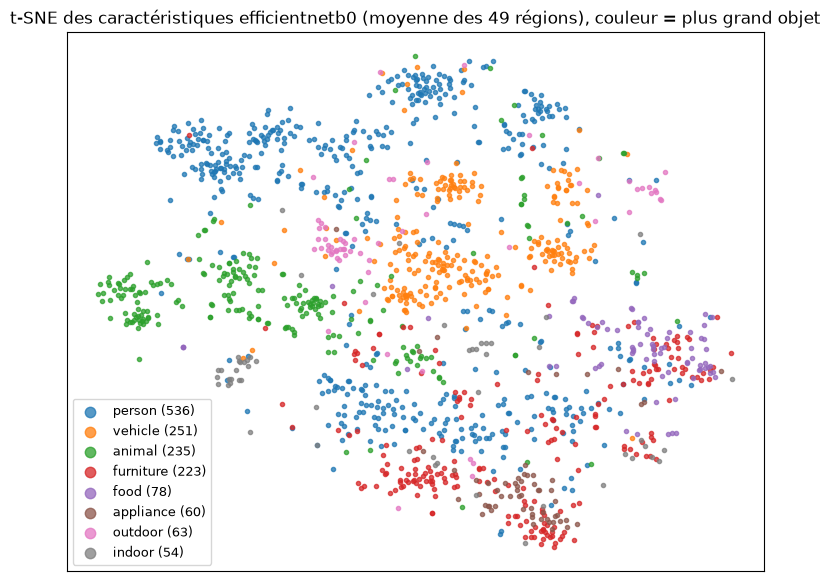

In [7]:
fichier_instances = COCO_DIR / "annotations" / "instances_train2014.json"
if not fichier_instances.is_file():
    print(f"{fichier_instances} absent : expérience sautée (elle ne sert qu'à illustrer le transfer learning)")
else:
    from sklearn.linear_model import LogisticRegression
    from sklearn.manifold import TSNE
    from sklearn.model_selection import cross_val_score

    import re
    # Le fichier fait 330 Mo, surtout à cause des contours des objets : json.load prendrait plusieurs Go de mémoire.
    # On n'a besoin que de trois valeurs par objet (aire, image, catégorie) : on les lit directement dans le texte,
    # par morceaux de 16 Mo (un objet coupé entre deux morceaux est relu grâce au recouvrement de 64 Ko).
    motif_objet = re.compile(r'"area":\s*([0-9.eE+-]+),\s*"iscrowd":\s*\d+,\s*"image_id":\s*(\d+),'
                             r'\s*"bbox":\s*\[[^\]]*\],\s*"category_id":\s*(\d+)')
    motif_cat = re.compile(r'\{"supercategory":\s*"([^"]+)",\s*"id":\s*(\d+)')
    plus_grand, super_cat, reste = {}, {}, ""          # image_id -> (aire, catégorie) du plus grand objet
    with open(fichier_instances, encoding="utf-8") as f:
        while True:
            morceau = f.read(16 * 2**20)
            texte = reste + morceau
            for aire, image_id, cat in motif_objet.findall(texte):
                aire, image_id = float(aire), int(image_id)
                if aire > plus_grand.get(image_id, (0, None))[0]:
                    plus_grand[image_id] = (aire, int(cat))
            super_cat.update({int(i): sc for sc, i in motif_cat.findall(texte)})
            if not morceau:
                break
            reste = texte[-65536:]
    plus_grand = {i: (a, super_cat[c]) for i, (a, c) in plus_grand.items()}
    print(f"{len(plus_grand)} images avec au moins un objet annoté, {len(set(super_cat.values()))} super-catégories")
    ids = [int(n[-16:-4]) for n in noms_images]
    etiquettes = np.array([plus_grand.get(i, (0, "aucun objet"))[1] for i in ids])
    frequentes = [c for c, _ in collections.Counter(etiquettes).most_common(8)]
    garde = np.isin(etiquettes, frequentes)
    vecteurs = FEATURES.mean(axis=1, dtype=np.float32)[garde]        # (N, 1280) : moyenne des 49 régions

    sonde = cross_val_score(LogisticRegression(max_iter=2000), vecteurs, etiquettes[garde], cv=5)
    hasard = max(collections.Counter(etiquettes[garde]).values()) / garde.sum()
    print(f"Sonde linéaire, 8 super-catégories : {sonde.mean():.1%} de bonnes réponses "
          f"(validation croisée 5 plis) ; toujours répondre la plus fréquente : {hasard:.1%}")

    sous = np.random.default_rng(SEED).permutation(len(vecteurs))[:1500]
    points = TSNE(n_components=2, init="pca", perplexity=30, random_state=SEED).fit_transform(vecteurs[sous])
    plt.figure(figsize=(9, 7))
    for c, couleur in zip(frequentes, plt.cm.tab10.colors):
        m = etiquettes[garde][sous] == c
        plt.scatter(points[m, 0], points[m, 1], s=9, color=couleur, label=f"{c} ({m.sum()})", alpha=0.75)
    plt.legend(markerscale=2.5, fontsize=9); plt.xticks([]); plt.yticks([])
    plt.title(f"t-SNE des caractéristiques {base.name} (moyenne des {N_REGIONS} régions), couleur = plus grand objet")
    plt.show()

Les images se regroupent par contenu (animaux, véhicules, nourriture, scènes de sport...) alors que le CNN n'a jamais
été entraîné sur COCO, et une sonde linéaire reconnaît la super-catégorie bien mieux que le hasard. **La partie
« vision » fonctionne** : le CNN pré-entraîné fournit au décodeur une description riche de l'image. Si le modèle complet
échoue (partie 7), ce sera surtout à cause de la partie « langage », entraînée de zéro.

## 3. Prétraitement du texte

Un réseau ne lit pas des mots, il lit des nombres. Comme dans le workshop :

1. **Vocabulaire** : on garde les `TOP_K = 5000` mots les plus fréquents des légendes d'**entraînement**. Tout autre mot
   devient le jeton `<unk>` (inconnu). Le jeton `<pad>` (indice 0) sert à compléter les légendes courtes.
2. **Jetons** : chaque légende devient une liste d'entiers, `<start>` ... `<end>` compris.
3. **Complétion** (*padding*) : toutes les légendes sont complétées par des 0 jusqu'à `MAX_MOTS + 2` jetons, pour former
   des tableaux rectangulaires ; la perte ignorera ces 0.

Le workshop utilisait `tf.keras.preprocessing.text.Tokenizer`, retiré de Keras 3. La petite classe `Vocabulaire`
ci-dessous refait exactement la même chose (mêmes règles de découpage, mêmes indices : `<unk>` = 1, puis les mots du
plus fréquent au moins fréquent), sans dépendre d'une version de Keras.

### Découpage entraînement / validation / test

Le workshop séparait 80 % / 20 % **sans graine** (découpage différent à chaque exécution) et **sans jeu de validation** :
impossible de voir le sur-apprentissage pendant l'entraînement, ni de choisir l'époque d'arrêt sans tricher sur le
test. Ici, découpage **par image** (les 5 légendes d'une image restent ensemble) et reproductible :

| Jeu | Part des images | Rôle |
|---|---|---|
| entraînement | 80 % | mise à jour des poids |
| validation | 10 % | surveiller le sur-apprentissage, choisir l'époque (early stopping) |
| test | 10 % | mesure finale, jamais utilisée pour un choix |

Le vocabulaire n'est construit qu'avec les légendes d'entraînement (pas de fuite d'information vers le test).

In [8]:
class Vocabulaire:
    "Équivalent du Tokenizer Keras du workshop (num_words=TOP_K, oov_token='<unk>', mêmes filtres de ponctuation)."
    PAD, UNK = "<pad>", "<unk>"

    def __init__(self, num_words, mot_vers_id=None):
        self.num_words = num_words
        self.mot_vers_id = mot_vers_id or {}
        self.id_vers_mot = {i: m for m, i in self.mot_vers_id.items()}

    def apprendre(self, textes):
        compte = collections.Counter(m for t in textes for m in mots(t))
        tries = sorted(compte.items(), key=lambda kv: -kv[1])          # tri stable : à égalité, ordre d'apparition
        self.mot_vers_id = {self.PAD: 0, self.UNK: 1, **{m: i + 2 for i, (m, _) in enumerate(tries)}}
        self.id_vers_mot = {i: m for m, i in self.mot_vers_id.items()}
        return self

    def encoder(self, texte):
        ids = (self.mot_vers_id.get(m, 1) for m in mots(texte))
        return [i if i < self.num_words else 1 for i in ids]           # mot trop rare -> <unk>

    def phrase(self, ids):
        "Liste d'indices -> liste de mots, sans <pad>, <start> ni <end>."
        out = []
        for i in ids:
            m = self.id_vers_mot.get(int(i), self.UNK)
            if m == "<end>":
                break
            if m not in (self.PAD, "<start>"):
                out.append(m)
        return out

    def sauver(self, chemin):
        garde = {m: i for m, i in self.mot_vers_id.items() if i < self.num_words}
        pathlib.Path(chemin).write_text(json.dumps({"num_words": self.num_words, "mot_vers_id": garde,
                                                    "max_jetons": MAX_MOTS + 2, "cnn": CNN}, ensure_ascii=False), encoding="utf-8")

    @classmethod
    def charger(cls, chemin):
        d = json.loads(pathlib.Path(chemin).read_text(encoding="utf-8"))
        return cls(d["num_words"], d["mot_vers_id"])


# Découpage par image, reproductible
ordre = noms_images[:]
random.Random(SEED).shuffle(ordre)
n_train, n_val = int(0.8 * len(ordre)), int(0.1 * len(ordre))
images_train, images_val, images_test = ordre[:n_train], ordre[n_train:n_train + n_val], ordre[n_train + n_val:]
if N_EVAL:
    images_test = images_test[:N_EVAL]

encadrer = lambda l: f"<start> {l} <end>"
if not RETRAIN and FICHIERS_MODELE_1["vocabulaire"].exists():
    vocab = Vocabulaire.charger(FICHIERS_MODELE_1["vocabulaire"])
else:
    vocab = Vocabulaire(TOP_K).apprendre(encadrer(l) for n in images_train for l in legendes_par_image[n])
START, END = vocab.mot_vers_id["<start>"], vocab.mot_vers_id["<end>"]
MAX_JETONS = MAX_MOTS + 2


def paires(images):
    "(indice de l'image, légende en jetons complétée) pour chaque légende d'au plus MAX_MOTS mots."
    idx, seqs = [], []
    for n in images:
        for l in legendes_par_image[n]:
            s = vocab.encoder(encadrer(l))
            if len(s) <= MAX_JETONS:
                idx.append(INDEX[n])
                seqs.append(s + [0] * (MAX_JETONS - len(s)))
    return np.array(idx, np.int32), np.array(seqs, np.int32)


idx_train, cap_train = paires(images_train)
idx_val, cap_val = paires(images_val)
idx_test, cap_test = paires(images_test)
mots_train = collections.Counter(m for n in images_train for l in legendes_par_image[n] for m in mots(l))
print(f"Images : {len(images_train)} entraînement, {len(images_val)} validation, {len(images_test)} test")
print(f"Légendes : {len(cap_train)} entraînement, {len(cap_val)} validation, {len(cap_test)} test")
print(f"{len(mots_train)} mots différents dans les légendes d'entraînement ; les {TOP_K - 2} plus fréquents couvrent "
      f"{sum(c for _, c in mots_train.most_common(TOP_K - 2)) / sum(mots_train.values()):.1%} des mots")
print("Exemple :", legendes_par_image[images_train[0]][0])
print("    ->", cap_train[0].tolist())
print("    ->", " ".join(vocab.id_vers_mot.get(int(i), "?") for i in cap_train[0]))

Images : 2888 entraînement, 361 validation, 362 test
Légendes : 14348 entraînement, 1797 validation, 1793 test
5642 mots différents dans les légendes d'entraînement ; les 4998 plus fréquents couvrent 99.6% des mots
Exemple : A man with glass, a suit and tie on smiling for a photo.
    -> [3, 2, 13, 9, 140, 2, 259, 10, 176, 5, 286, 85, 2, 161, 4, 0, 0, 0, 0, 0, 0, 0]
    -> <start> a man with glass a suit and tie on smiling for a photo <end> <pad> <pad> <pad> <pad> <pad> <pad> <pad>


## 4. Modèle 1 : encodeur CNN + attention + décodeur GRU (workshop Annotation d'images)

C'est l'architecture « *Show, Attend and Tell* » (Xu et al., 2015) du workshop. La légende est produite **un mot à la
fois** ; à chaque pas, le décodeur regarde l'image entière, choisit sur quelles régions se concentrer (l'attention), et
prédit le mot suivant.

```
                         ┌────────────── état caché h(t-1) ───────────────┐
                         ▼                                                 │
 49 régions ──► Encodeur ──► Attention ──► contexte c(t) ─┐                │
 (cache .npy)   Dense 256      α = poids                  ├─► concat ──► GRU ──► h(t) ──► Dense 512 ──► Dense 5000 ──► mot t
                               des régions   mot (t-1) ──► Embedding 256 ┘                                  (scores)
```

**Encodeur CNN.** Les 49 vecteurs de 1280 valeurs passent dans une couche dense (+ ReLU) qui les ramène à 256 valeurs.
Les régions ne sont **pas aplaties** en un seul vecteur : l'information spatiale est gardée pour l'attention.

**Attention de Bahdanau.** À chaque pas $t$, avec $f_i$ les 49 régions encodées et $h_{t-1}$ l'état caché du GRU :

$$e_{t,i} = v^\top \tanh\!\big(W_1 f_i + W_2 h_{t-1}\big), \qquad
\alpha_{t,i} = \frac{\exp e_{t,i}}{\sum_j \exp e_{t,j}}, \qquad
c_t = \sum_{i=1}^{49} \alpha_{t,i}\, f_i$$

Le score $e_{t,i}$ dit combien la région $i$ est utile **compte tenu de ce qui a déjà été écrit** ; le softmax en fait des
poids positifs de somme 1 ; le **vecteur de contexte** $c_t$ est la moyenne des régions pondérée par ces poids.

**Décodeur GRU.** Le mot précédent passe dans une couche d'**embedding** (un vecteur appris de 256 valeurs par mot), est
concaténé au contexte $c_t$, puis entre dans un **GRU** (*Gated Recurrent Unit*). Le GRU tient une mémoire $h_t$ de ce qui
a été dit, mise à jour par deux portes :

$$z_t = \sigma(W_z x_t + U_z h_{t-1}), \quad r_t = \sigma(W_r x_t + U_r h_{t-1}), \quad
\tilde h_t = \tanh\!\big(W x_t + U (r_t \odot h_{t-1})\big), \quad h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde h_t$$

La porte de mise à jour $z_t$ décide quelle part de la mémoire garder, la porte de remise à zéro $r_t$ quelle part
utiliser pour le candidat $\tilde h_t$. Deux couches denses transforment enfin $h_t$ en un **score par mot du
vocabulaire** ; le softmax de ces scores donne la probabilité de chaque mot suivant.

In [9]:
class CNN_Encoder(tf.keras.Model):
    "Les caractéristiques du CNN (déjà calculées) passent dans une couche dense + ReLU : (lot, 49, 1280) -> (lot, 49, 256)."
    def __init__(self, embedding_dim):
        super().__init__()
        self.fc = tf.keras.layers.Dense(embedding_dim)

    def call(self, x):
        return tf.nn.relu(self.fc(x))


class BahdanauAttention(tf.keras.Model):
    "Attention additive : un poids par région selon l'état caché, puis moyenne pondérée des régions."
    def __init__(self, units):
        super().__init__()
        self.W1 = tf.keras.layers.Dense(units)
        self.W2 = tf.keras.layers.Dense(units)
        self.V = tf.keras.layers.Dense(1)

    def call(self, features, hidden):
        # features : (lot, 49, 256) ; hidden : (lot, units) -> (lot, 1, units) pour s'ajouter à chaque région
        hidden_with_time_axis = tf.expand_dims(hidden, 1)
        attention_hidden_layer = tf.nn.tanh(self.W1(features) + self.W2(hidden_with_time_axis))   # (lot, 49, units)
        score = self.V(attention_hidden_layer)                                                      # (lot, 49, 1) : e
        attention_weights = tf.nn.softmax(score, axis=1)                                            # alpha, somme 1
        context_vector = tf.reduce_sum(attention_weights * features, axis=1)                        # (lot, 256) : c
        return context_vector, attention_weights


class RNN_Decoder(tf.keras.Model):
    "Un pas de décodage : mot précédent + image + état caché -> scores du mot suivant, nouvel état, poids d'attention."
    def __init__(self, embedding_dim, units, vocab_size):
        super().__init__()
        self.units = units
        self.embedding = tf.keras.layers.Embedding(vocab_size, embedding_dim)
        self.gru = tf.keras.layers.GRU(units, return_sequences=True, return_state=True, recurrent_initializer="glorot_uniform")
        self.fc1 = tf.keras.layers.Dense(units)
        self.fc2 = tf.keras.layers.Dense(vocab_size)
        self.attention = BahdanauAttention(units)

    def call(self, x, features, hidden):
        context_vector, attention_weights = self.attention(features, hidden)
        x = self.embedding(x)                                                    # (lot, 1, 256)
        x = tf.concat([tf.expand_dims(context_vector, 1), x], axis=-1)           # (lot, 1, 512)
        output, state = self.gru(x, initial_state=hidden)                        # (lot, 1, units), (lot, units)
        y = self.fc1(output)
        y = tf.reshape(y, (-1, y.shape[2]))
        y = self.fc2(y)                                                          # (lot, vocab) : scores (logits)
        return y, state, attention_weights

    def reset_state(self, batch_size):
        return tf.zeros((batch_size, self.units))


encoder = CNN_Encoder(EMBEDDING)
decoder = RNN_Decoder(EMBEDDING, UNITS, TOP_K)
# Un premier passage crée les poids (nécessaire pour les compter, les enregistrer ou les recharger)
_f = encoder(tf.zeros((1, N_REGIONS, N_CANAUX)))
_ = decoder(tf.fill([1, 1], START), _f, decoder.reset_state(1))
parametres = {
    "encodeur (Dense 1280 -> 256)": encoder.count_params(),
    "attention (W1, W2, V)": decoder.attention.count_params(),
    "embedding des mots": decoder.embedding.count_params(),
    "GRU": decoder.gru.count_params(),
    "Dense 512 + Dense vers le vocabulaire": decoder.fc1.count_params() + decoder.fc2.count_params(),
}
print(pd.Series(parametres, name="paramètres entraînés").to_string())
print(f"Total entraîné : {sum(parametres.values()):,} paramètres (+ {base.count_params():,} gelés dans {base.name})")

encodeur (Dense 1280 -> 256)              327936
attention (W1, W2, V)                     394753
embedding des mots                       1280000
GRU                                      1575936
Dense 512 + Dense vers le vocabulaire    2827656
Total entraîné : 6,406,281 paramètres (+ 4,049,571 gelés dans efficientnetb0)


## 5. Entraînement

**Teacher forcing.** À l'entraînement, le mot donné au décodeur au pas $t$ est le **vrai** mot $t-1$ de la légende, pas
celui qu'il a prédit : chaque pas apprend indépendamment des erreurs des pas précédents, ce qui accélère beaucoup
l'apprentissage. (Revers de la médaille, partie 7 : en production, le décodeur ne reçoit que ses propres mots.)

**Perte.** Entropie croisée entre le score des mots et le vrai mot suivant, $-\log p(\text{vrai mot})$, **moyennée sur
les seuls vrais mots** : les positions `<pad>` sont masquées. On affiche cette perte par mot ; $e^{\text{perte}}$ est la
**perplexité**, le nombre de mots entre lesquels le modèle « hésite » en moyenne (1 = certitude).

> Le workshop divisait la somme des pertes de chaque pas par la longueur complétée (50 jetons) : la perte affichée
> (0,06 en fin d'entraînement) était plusieurs fois plus petite que la vraie perte par mot (la plupart des 50 pas ne sont que du
> remplissage) et ne pouvait pas être
> comparée d'une configuration à l'autre.

**Optimiseur : Adam** (pas $3 \cdot 10^{-4}$, comme le workshop), qui combine un momentum et un pas propre à chaque poids.

**Early stopping.** À chaque époque on calcule aussi la perte sur le jeu de **validation** ; on garde les poids de la
meilleure époque et on s'arrête après `PATIENCE` époques sans progrès. Les poids sont **enregistrés dans `models/` à
chaque nouvelle meilleure époque**, donc aussi en fin d'entraînement.

> Autre correction : le workshop reprenait l'entraînement à l'époque « numéro du dernier checkpoint », alors qu'il
> enregistrait un checkpoint toutes les deux époques ; après une interruption, le compte des époques était faux.

In [10]:
optimizer = tf.keras.optimizers.Adam(learning_rate=LR)
loss_object = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True, reduction="none")


def perte_lot(img_tensor, target, entrainement):
    "Somme des pertes des vrais mots d'un lot et nombre de vrais mots (teacher forcing)."
    features = encoder(tf.cast(img_tensor, tf.float32), training=entrainement)
    hidden = decoder.reset_state(tf.shape(target)[0])
    dec_input = tf.expand_dims(target[:, 0], 1)                  # <start>
    total, n = 0.0, 0.0
    for i in range(1, target.shape[1]):
        predictions, hidden, _ = decoder(dec_input, features, hidden, training=entrainement)
        masque = tf.cast(tf.not_equal(target[:, i], 0), tf.float32)
        total += tf.reduce_sum(loss_object(target[:, i], predictions) * masque)
        n += tf.reduce_sum(masque)
        dec_input = tf.expand_dims(target[:, i], 1)              # le vrai mot i est l'entrée du pas i + 1
    return total, n


SIGNATURE = [tf.TensorSpec([None, N_REGIONS, N_CANAUX], tf.float16), tf.TensorSpec([None, MAX_JETONS], tf.int32)]

@tf.function(input_signature=SIGNATURE)
def train_step(img_tensor, target):
    with tf.GradientTape() as tape:
        total, n = perte_lot(img_tensor, target, True)
        loss = total / tf.maximum(n, 1.0)
    variables = encoder.trainable_variables + decoder.trainable_variables
    optimizer.apply_gradients(zip(tape.gradient(loss, variables), variables))
    return total, n

@tf.function(input_signature=SIGNATURE)
def eval_step(img_tensor, target):
    return perte_lot(img_tensor, target, False)


def lots(idx, caps, melanger):
    ds = tf.data.Dataset.from_tensor_slices((idx, caps))
    if melanger:
        ds = ds.shuffle(len(idx), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)


def perte_moyenne(idx, caps):
    "Perte moyenne par mot sur tout un jeu, sans mise à jour des poids."
    total = n = 0.0
    for i, c in lots(idx, caps, False):
        t, k = eval_step(FEATURES[i.numpy()], c)
        total, n = total + float(t), n + float(k)
    return total / n

In [11]:
def enregistrer_modele_1(historique):
    encoder.save_weights(FICHIERS_MODELE_1["encodeur"])
    decoder.save_weights(FICHIERS_MODELE_1["decodeur"])
    vocab.sauver(FICHIERS_MODELE_1["vocabulaire"])
    pd.DataFrame(historique).to_csv(FICHIERS_MODELE_1["historique"], index=False)

deja_entraine = all(FICHIERS_MODELE_1[k].exists() for k in ("encodeur", "decodeur", "vocabulaire", "historique"))
if not RETRAIN and deja_entraine:
    encoder.load_weights(FICHIERS_MODELE_1["encodeur"])
    decoder.load_weights(FICHIERS_MODELE_1["decodeur"])
    historique = pd.read_csv(FICHIERS_MODELE_1["historique"]).to_dict("list")
    print(f"Modèle 1 rechargé depuis {MODELS_DIR.resolve()} ({len(historique['epoque'])} époques d'entraînement)")
else:
    historique = {"epoque": [], "perte_train": [], "perte_val": [], "duree_s": []}
    meilleure, sans_progres, meilleurs_poids = math.inf, 0, None
    debut = time.time()
    for epoque in range(1, EPOCHS + 1):
        t0, total, n = time.time(), 0.0, 0.0
        for i, c in lots(idx_train, cap_train, True):
            t, k = train_step(FEATURES[i.numpy()], c)      # caractéristiques du lot (float16)
            total, n = total + float(t), n + float(k)
        perte_val = perte_moyenne(idx_val, cap_val)
        for cle, v in zip(historique, (epoque, total / n, perte_val, time.time() - t0)):
            historique[cle].append(v)
        marque = ""
        if perte_val < meilleure - 1e-4:
            meilleure, sans_progres, marque = perte_val, 0, "  <- meilleure, enregistrée"
            meilleurs_poids = (encoder.get_weights(), decoder.get_weights())
            enregistrer_modele_1(historique)
        else:
            sans_progres += 1
        print(f"Époque {epoque:2d} : perte entraînement {total / n:.3f} (perplexité {math.exp(total / n):5.1f}), "
              f"validation {perte_val:.3f} (perplexité {math.exp(perte_val):5.1f}), {time.time() - t0:.0f} s{marque}")
        if sans_progres >= PATIENCE:
            print(f"Arrêt : {PATIENCE} époques sans progrès de la validation")
            break
    encoder.set_weights(meilleurs_poids[0]); decoder.set_weights(meilleurs_poids[1])
    pd.DataFrame(historique).to_csv(FICHIERS_MODELE_1["historique"], index=False)
    print(f"Entraînement : {(time.time() - debut) / 60:.1f} min ; poids de l'époque "
          f"{historique['epoque'][int(np.argmin(historique['perte_val']))]} gardés et enregistrés dans {MODELS_DIR.resolve()}")
liberer_memoire("après l'entraînement")


E0000 00:00:1792710270.623804    1039 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


Époque  1 : perte entraînement 5.076 (perplexité 160.1), validation 4.140 (perplexité  62.8), 31 s  <- meilleure, enregistrée
Époque  2 : perte entraînement 3.795 (perplexité  44.5), validation 3.618 (perplexité  37.2), 21 s  <- meilleure, enregistrée
Époque  3 : perte entraînement 3.346 (perplexité  28.4), validation 3.441 (perplexité  31.2), 21 s  <- meilleure, enregistrée
Époque  4 : perte entraînement 3.047 (perplexité  21.1), validation 3.364 (perplexité  28.9), 21 s  <- meilleure, enregistrée
Époque  5 : perte entraînement 2.805 (perplexité  16.5), validation 3.335 (perplexité  28.1), 21 s  <- meilleure, enregistrée
Époque  6 : perte entraînement 2.601 (perplexité  13.5), validation 3.337 (perplexité  28.1), 22 s
Époque  7 : perte entraînement 2.424 (perplexité  11.3), validation 3.368 (perplexité  29.0), 21 s
Époque  8 : perte entraînement 2.271 (perplexité   9.7), validation 3.446 (perplexité  31.4), 21 s
Arrêt : 3 époques sans progrès de la validation
Entraînement : 3.0 min ; 

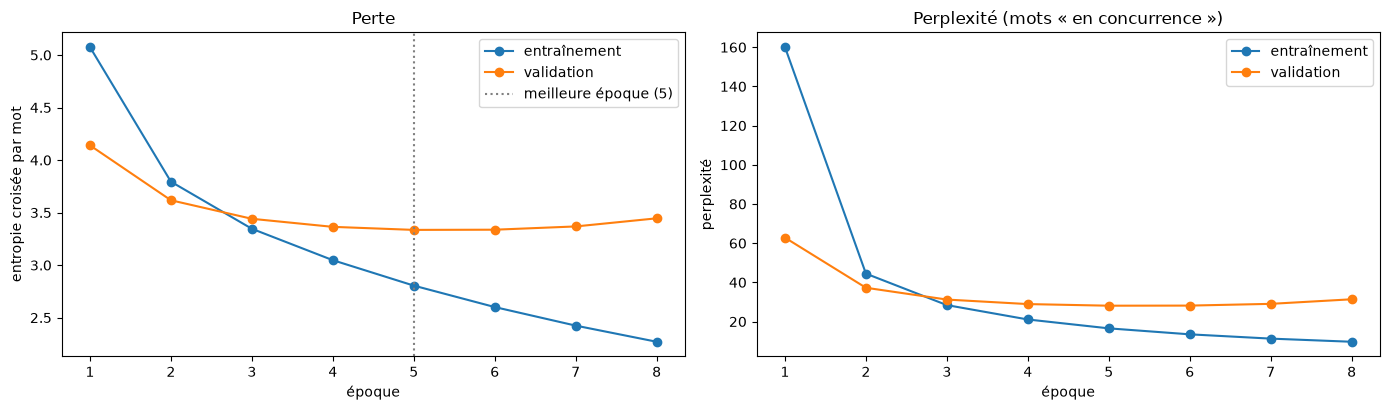

Meilleure époque 5 : perte entraînement 2.805, validation 3.335 ; dernière époque : entraînement 2.271, validation 3.446


In [12]:
h = pd.DataFrame(historique)
best = int(h["perte_val"].idxmin())
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(h["epoque"], h["perte_train"], "o-", label="entraînement")
ax[0].plot(h["epoque"], h["perte_val"], "o-", label="validation")
ax[0].axvline(h["epoque"][best], color="gray", ls=":", label=f"meilleure époque ({h['epoque'][best]})")
ax[0].set_xlabel("époque"); ax[0].set_ylabel("entropie croisée par mot"); ax[0].legend(); ax[0].set_title("Perte")
ax[1].plot(h["epoque"], np.exp(h["perte_train"]), "o-", label="entraînement")
ax[1].plot(h["epoque"], np.exp(h["perte_val"]), "o-", label="validation")
ax[1].set_xlabel("époque"); ax[1].set_ylabel("perplexité"); ax[1].legend(); ax[1].set_title("Perplexité (mots « en concurrence »)")
plt.tight_layout(); plt.show()
print(f"Meilleure époque {h['epoque'][best]} : perte entraînement {h['perte_train'][best]:.3f}, validation {h['perte_val'][best]:.3f} ; "
      f"dernière époque : entraînement {h['perte_train'].iloc[-1]:.3f}, validation {h['perte_val'].iloc[-1]:.3f}")

### Lecture des courbes

* La perte d'**entraînement** baisse à chaque époque (de 5,08 à 2,27 ; perplexité de 160 à 9,7) : le réseau apprend
  de mieux en mieux **ses** 14 348 légendes.
* La perte de **validation** ne baisse plus après la **5e époque** (3,33, perplexité 28) puis remonte (3,44 à la 8e) :
  à partir de là, le modèle apprend par cœur les légendes d'entraînement au lieu de généraliser. C'est du
  **sur-apprentissage** (forte variance), et l'early stopping garde les poids de l'époque 5.
* Même à ce meilleur moment, une perplexité de 28 veut dire qu'à chaque mot le modèle hésite encore entre une
  trentaine de mots, en moyenne, sur des images qu'il n'a pas vues.

Le workshop entraînait 60 époques sans jeu de validation : sa perte d'entraînement continuait de baisser, ce qui
donnait l'illusion d'un modèle de plus en plus bon, alors qu'au-delà de 5 époques il se dégradait sur les images
nouvelles.

## 6. Évaluation du modèle 1

### Produire une légende

En production il n'y a plus de vraie légende : le décodeur part de `<start>` et **reçoit à chaque pas le mot qu'il vient
de prédire**, jusqu'à `<end>` ou `MAX_MOTS` mots. Deux façons de choisir le mot :

* **glouton** : le mot le plus probable à chaque pas ;
* **recherche en faisceau** (largeur 3, comme le workshop) : on garde à chaque pas les 3 débuts de phrase les plus
  probables, et à la fin la phrase de meilleure probabilité, divisée par sa longueur à la puissance 0,7 pour ne pas
  favoriser les phrases trop courtes.

> Correction du workshop : sa recherche en faisceau **interdisait de réutiliser un mot déjà écrit**, pour éviter les
> boucles (« a man and a man and... »). Cela rendait impossibles des phrases normales comme « **a** man riding **a**
> horse ». On interdit ici seulement de répéter une même **paire** de mots, la règle qu'utilise aussi BLIP
> (`no_repeat_ngram_size=2`, partie 8) : les deux modèles sont décodés de la même façon.

In [13]:
def legendes_glouton(indices, lot=128):
    "Légendes gloutonnes (une liste de mots par image) pour des lignes du tableau FEATURES."
    out = []
    for d in range(0, len(indices), lot):
        f = encoder(tf.cast(FEATURES[indices[d:d + lot]], tf.float32), training=False)
        b = f.shape[0]
        hidden, x, ids = decoder.reset_state(b), tf.fill([b, 1], START), []
        for _ in range(MAX_JETONS - 1):
            pred, hidden, _ = decoder(x, f, hidden, training=False)
            x = tf.argmax(pred, axis=-1, output_type=tf.int32)[:, None]
            ids.append(x[:, 0])
        out += [vocab.phrase(r) for r in tf.stack(ids, axis=1).numpy()]
    return out


def legende_faisceau(feature, largeur=LARGEUR_FAISCEAU, alpha=0.7, sans_repetition=2):
    "Recherche en faisceau pour une image (feature : régions x canaux). Renvoie (mots, poids d'attention par mot)."
    f = encoder(tf.cast(feature[None], tf.float32), training=False)
    faisceaux, termines = [([START], 0.0, decoder.reset_state(1), [])], []
    note = lambda c: c[1] / max(1, len(c[0]) - 1) ** alpha
    for _ in range(MAX_JETONS - 1):
        candidats = []
        for ids, score, hidden, att in faisceaux:
            pred, h2, a = decoder(tf.constant([[ids[-1]]]), f, hidden, training=False)
            logp = tf.nn.log_softmax(pred[0]).numpy()
            logp[[0, 1, START]] = -np.inf                     # ni <pad>, ni <unk>, ni <start>
            if sans_repetition == 2:                          # pas deux fois la même paire de mots
                for j in range(len(ids) - 1):
                    if ids[j] == ids[-1]:
                        logp[ids[j + 1]] = -np.inf
            for k in np.argsort(logp)[-largeur:]:
                candidats.append((ids + [int(k)], score + float(logp[k]), h2, att + [a.numpy().reshape(-1)]))
        candidats = sorted(candidats, key=note, reverse=True)[:largeur]
        termines += [c for c in candidats if c[0][-1] == END]
        faisceaux = [c for c in candidats if c[0][-1] != END]
        if len(termines) >= largeur or not faisceaux:
            break
    ids, _, _, att = max(termines or faisceaux, key=note)
    phrase = vocab.phrase(ids)
    return phrase, np.array(att[:len(phrase)])


i_test = np.array([INDEX[n] for n in images_test])
t0 = time.time()
glouton_test = legendes_glouton(i_test)
ms_glouton = (time.time() - t0) * 1000 / len(i_test)
t0 = time.time()
faisceau_test = [legende_faisceau(FEATURES[i])[0] for i in i_test]
ms_faisceau = (time.time() - t0) * 1000 / len(i_test)
print(f"{len(i_test)} images de test légendées : {ms_glouton:.1f} ms par image en glouton, {ms_faisceau:.0f} ms en faisceau "
      f"(hors passage dans {base.name})")
liberer_memoire("après l'évaluation")


362 images de test légendées : 1.7 ms par image en glouton, 257 ms en faisceau (hors passage dans efficientnetb0)
Mémoire occupée par le noyau après l'évaluation : 2.5 Go


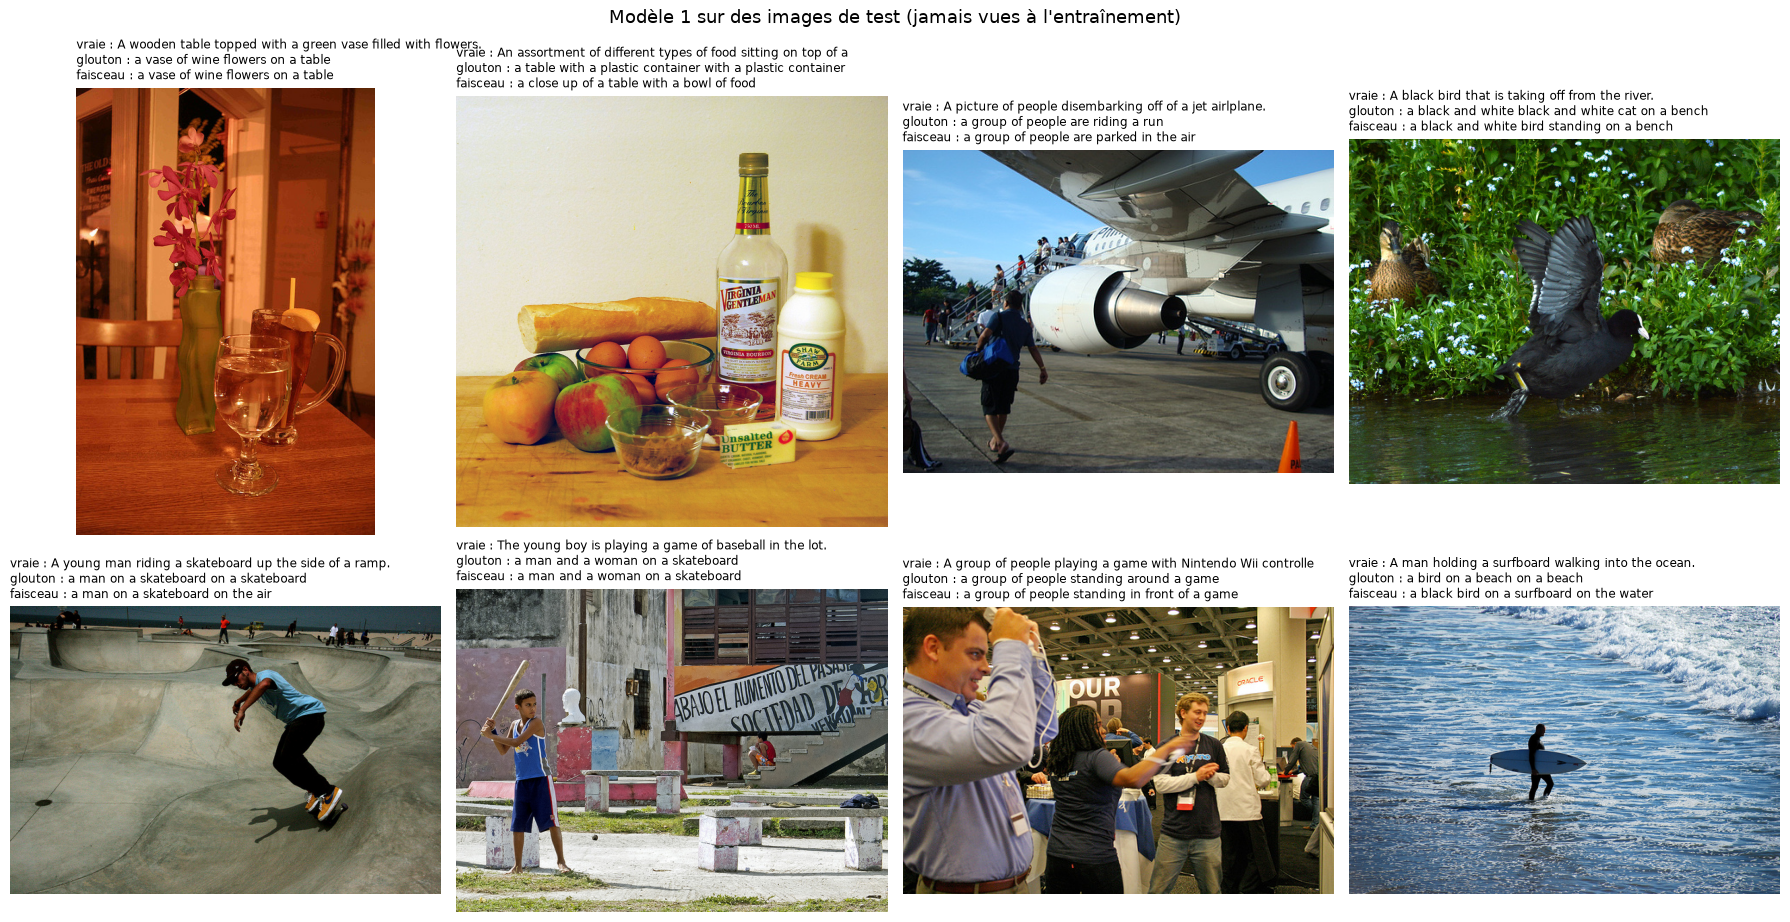

In [14]:
# Quelques images de test : une vraie légende (sur 5), puis les deux décodages du modèle 1
exemples = images_test[:8]
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
for ax, n in zip(axes.ravel(), exemples):
    k = images_test.index(n)
    ax.imshow(Image.open(chemins_images[n]).convert("RGB")); ax.axis("off")
    ax.set_title(f"vraie : {legendes_par_image[n][0][:60]}\nglouton : {' '.join(glouton_test[k])[:60]}\n"
                 f"faisceau : {' '.join(faisceau_test[k])[:60]}", fontsize=8.5, loc="left")
plt.suptitle("Modèle 1 sur des images de test (jamais vues à l'entraînement)", fontsize=13)
plt.tight_layout(); plt.show()

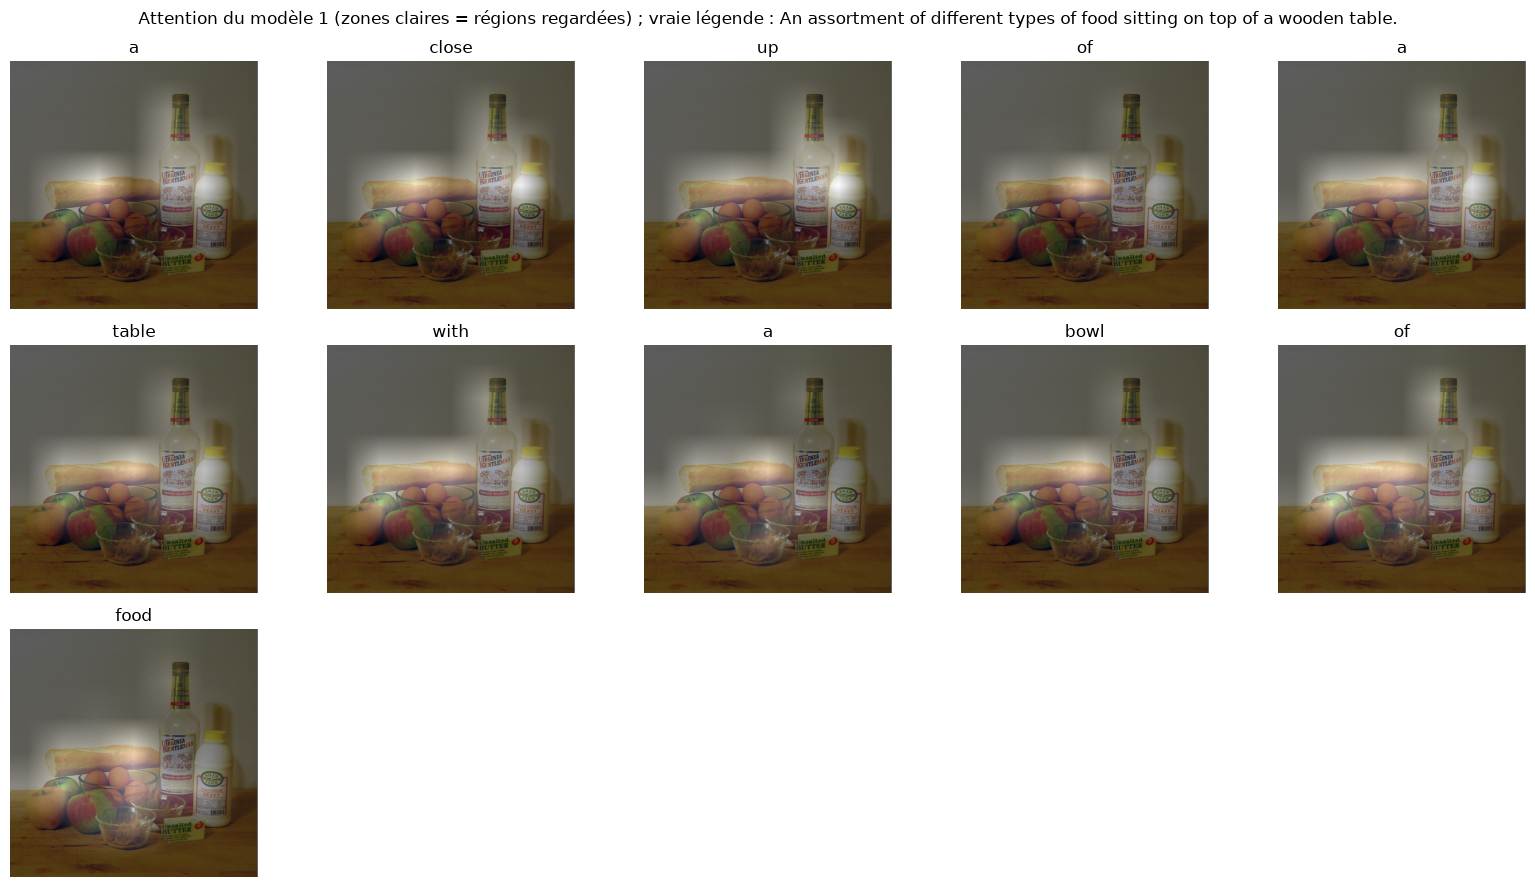

In [15]:
# Où le modèle regarde-t-il ? Poids d'attention (7 x 7 régions) de chaque mot généré, sur une image de test
def montrer_attention(nom):
    mots_generes, att = legende_faisceau(FEATURES[INDEX[nom]])
    img = np.array(Image.open(chemins_images[nom]).convert("RGB"))
    n = len(mots_generes)
    cols = 5
    fig = plt.figure(figsize=(3.2 * cols, 3 * math.ceil(n / cols)))
    for k in range(n):
        ax = fig.add_subplot(math.ceil(n / cols), cols, k + 1)
        ax.imshow(img)
        ax.imshow(att[k].reshape(H_CARTE, W_CARTE), cmap="gray", alpha=0.6, extent=(0, img.shape[1], img.shape[0], 0),
                  interpolation="bilinear")
        ax.set_title(mots_generes[k]); ax.axis("off")
    plt.suptitle(f"Attention du modèle 1 (zones claires = régions regardées) ; vraie légende : {legendes_par_image[nom][0]}")
    plt.tight_layout(); plt.show()

montrer_attention(images_test[1])

### Mesurer la qualité : BLEU et diversité

**BLEU** (Papineni et al., 2002), la mesure classique en traduction et en captioning, compare la phrase produite aux
**5 vraies légendes** de l'image : quelle part de ses mots (BLEU-1), de ses paires de mots (BLEU-2)... jusqu'aux suites de
4 mots (BLEU-4) se retrouve dans au moins une des références. Une pénalité punit les phrases trop courtes. 0 = rien en
commun, 1 = identique à une référence. BLEU-1 juge surtout le **vocabulaire** (les bons objets sont-ils nommés ?),
BLEU-4 la **justesse des tournures**. Pour situer : sur COCO, une phrase humaine comparée aux 4 autres obtient environ
0,2 en BLEU-4, les meilleurs modèles publiés dépassent 0,4.

BLEU ne voit pas tout : une légende passe-partout (« a man standing in a room ») marque des points sur beaucoup
d'images. On mesure donc aussi la **diversité** :

* **légendes distinctes** : un modèle qui donne la même phrase à des images différentes ne les regarde pas vraiment ;
* **mots utilisés** : la richesse du vocabulaire effectivement employé ;
* **phrases recopiées** : part des légendes identiques mot pour mot à une légende d'entraînement (signe de par cœur).

In [16]:
def ngrammes(m, n):
    return collections.Counter(tuple(m[i:i + n]) for i in range(len(m) - n + 1))


def bleu(candidats, references, n_max=4):
    "BLEU de corpus (Papineni et al., 2002) : précisions n-grammes écrêtées, moyenne géométrique, pénalité de brièveté."
    num, den, c, r = [0] * n_max, [0] * n_max, 0, 0
    for h, refs in zip(candidats, references):
        c += len(h)
        r += min((abs(len(x) - len(h)), len(x)) for x in refs)[1]       # longueur de la référence la plus proche
        for n in range(1, n_max + 1):
            compte, maxi = ngrammes(h, n), collections.Counter()
            for x in refs:
                maxi |= ngrammes(x, n)
            num[n - 1] += sum(min(k, maxi[g]) for g, k in compte.items())
            den[n - 1] += max(len(h) - n + 1, 0)
    if c == 0: 
        return {f"BLEU-{n}": 0.0 for n in range(1, n_max + 1)}
    bp = 1.0 if c > r else math.exp(1 - r / c)
    precisions = [num[k] / den[k] if den[k] and num[k] else 1e-9 for k in range(n_max)]
    return {f"BLEU-{n}": bp * math.exp(sum(math.log(p) for p in precisions[:n]) / n) for n in range(1, n_max + 1)}


phrases_train = {tuple(mots(l)) for n in images_train for l in legendes_par_image[n]}

def evaluer(nom, candidats, images, ms=None):
    refs = [[mots(l) for l in legendes_par_image[n]] for n in images]
    ligne = {"modèle": nom, **bleu(candidats, refs)}
    ligne["légendes distinctes"] = len({tuple(c) for c in candidats}) / len(candidats)
    ligne["mots utilisés"] = len({m for c in candidats for m in c})
    ligne["phrases recopiées de l'entraînement"] = np.mean([tuple(c) in phrases_train for c in candidats])
    ligne["mots par légende"] = np.mean([len(c) for c in candidats])
    if ms is not None:
        ligne["ms par image"] = ms
    return ligne


# Référence humaine : une des 5 légendes comparée aux 4 autres (le score qu'obtiendrait une personne)
humain = evaluer("légende humaine (1 contre 4)", [mots(legendes_par_image[n][0]) for n in images_test], images_test)
humain.update(bleu([mots(legendes_par_image[n][0]) for n in images_test],
                   [[mots(l) for l in legendes_par_image[n][1:]] for n in images_test]))

# Même mesure sur autant d'images d'ENTRAÎNEMENT que de test : l'écart entraînement / test mesure le sur-apprentissage
images_train_eval = images_train[:len(images_test)]
glouton_train = legendes_glouton(np.array([INDEX[n] for n in images_train_eval]))

resultats = pd.DataFrame([
    humain,
    evaluer("modèle 1, glouton, images d'entraînement", glouton_train, images_train_eval),
    evaluer("modèle 1, glouton, test", glouton_test, images_test, ms_glouton),
    evaluer("modèle 1, faisceau, test", faisceau_test, images_test, ms_faisceau),
]).set_index("modèle")
resultats.round(3)

,BLEU-1,BLEU-2,BLEU-3,BLEU-4,légendes distinctes,mots utilisés,phrases recopiées de l'entraînement,mots par légende,ms par image
modèle,,,,,,,,,
légende humaine (1 contre 4),0.632,0.438,0.298,0.202,0.994,873,0.014,10.768,NaN
"modèle 1, glouton, images d'entraînement",0.712,0.552,0.408,0.292,0.928,278,0.019,9.083,NaN
"modèle 1, glouton, test",0.591,0.413,0.281,0.191,0.906,224,0.008,9.075,1.740
"modèle 1, faisceau, test",0.622,0.441,0.305,0.211,0.892,250,0.033,8.743,257.045


In [17]:
# Les légendes les plus fréquentes du modèle 1 sur le jeu de test
frequentes = collections.Counter(" ".join(c) for c in faisceau_test).most_common(10)
print(f"Les 10 légendes les plus produites (faisceau) sur {len(faisceau_test)} images de test :")
for phrase, k in frequentes:
    print(f"  {k:3d} fois : {phrase}")

Les 10 légendes les plus produites (faisceau) sur 362 images de test :
   16 fois : a group of people sitting on a table
    3 fois : a group of people sitting at a table
    3 fois : a bathroom with a toilet and a sink
    2 fois : a group of people are playing a game
    2 fois : a group of people standing next to each other
    2 fois : a baseball player swinging a bat on a field
    2 fois : a group of people sitting on top of a table
    2 fois : a train and train on the tracks
    2 fois : a group of people sitting on a desk
    2 fois : a bowl of vegetables and vegetables on a table


### Sur les images du projet

Les 12 images de `Test_photos/` (photos, peintures, images « autres ») n'ont été vues par aucun modèle. Ce n'est plus
COCO : c'est le genre d'images que la pipeline recevra.

In [18]:
fichiers_projet = sorted(p for p in TEST_PHOTOS.glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"})
features_projet = caracteristiques([str(p) for p in fichiers_projet], lot=4)   # (12, 49, 1280), environ 1,5 Mo
modele1_projet = [" ".join(legende_faisceau(f)[0]) for f in features_projet]
for p, l in zip(fichiers_projet, modele1_projet):
    print(f"{p.name:28s} modèle 1 : {l}")
liberer_memoire("après les images du projet")


Jauconde.jpg                 modèle 1 : a woman in front of a luggage in the back
Terre.jpg                    modèle 1 : a small white box with a toilet on it
etrange.jpg                  modèle 1 : a close up of an orange trunk in the background
homme devant fenetre.jpg     modèle 1 : a man wearing a helmet on a skateboard in the park
nuit sous les étoiles.jpg    modèle 1 : a bunch of umbrellas in a green park
peinture wiki.jpg            modèle 1 : a group of people sitting on top of a river
photo1.jpg                   modèle 1 : a woman is standing on top of a field
photo2.jpg                   modèle 1 : a person on a beach in the water
photo3.jpg                   modèle 1 : a woman is on a bench in the woods
photo4.jpg                   modèle 1 : a group of people walking in the middle of a building
tropius.jpg                  modèle 1 : a group of people sitting on top of a lot
voie_lactée.jpg              modèle 1 : a black and white photo of a man in the background
Mémoire

### Résultats enregistrés pour la partie 2

`L3_2_BLIP.ipynb` compare BLIP au modèle 1 **sur les mêmes images**. Ce notebook-ci lui laisse donc, dans
`models/l3_attention_resultats.json`, la liste des images de test, les légendes du modèle 1 (glouton et faisceau, images
de test et images du projet) et le tableau des scores. Le second notebook n'a ainsi besoin ni de TensorFlow, ni de
ré-entraîner le modèle 1.

In [19]:
export = {
    "parametres": {"SEED": SEED, "MAX_IMAGES": MAX_IMAGES, "N_EVAL": N_EVAL, "CNN": CNN, "TOP_K": TOP_K, "MAX_MOTS": MAX_MOTS},
    "images_test": images_test,
    "exemples": exemples,
    "glouton_test": [" ".join(c) for c in glouton_test],
    "faisceau_test": [" ".join(c) for c in faisceau_test],
    "projet": {p.name: l for p, l in zip(fichiers_projet, modele1_projet)},
    "resultats": resultats.reset_index().to_dict("records"),
    "epoques": len(historique["epoque"]),
    "entrainement_min": float(np.sum(historique["duree_s"])) / 60,
    "parametres_entraines": int(sum(parametres.values())),
}
FICHIERS_MODELE_1["resultats"].write_text(json.dumps(export, ensure_ascii=False, indent=1, default=float), encoding="utf-8")
print(f"Résultats du modèle 1 enregistrés dans {FICHIERS_MODELE_1['resultats'].resolve()} "
      f"({len(images_test)} images de test, {len(fichiers_projet)} images du projet)")

Résultats du modèle 1 enregistrés dans /mnt/d/A5/projet/models/l3_attention_resultats.json (362 images de test, 12 images du projet)


## 7. Diagnostic : pourquoi le modèle 1 ne fonctionne pas

### Ce que l'on observe

**1. Sur COCO, un score BLEU trompeur.** En recherche en faisceau, le modèle 1 obtient un BLEU-4 de **0,209** sur les
362 images de test, au niveau d'une légende humaine comparée aux quatre autres (0,202). Ce chiffre ne veut pas dire
que les légendes sont justes : BLEU compte les suites de mots communes avec les références, et les tournures
stéréotypées de COCO (« a group of people », « sitting on a table », « on top of ») rapportent des points même
quand la phrase décrit autre chose. Les exemples de la partie 6 le montrent :

| Image (vraie légende) | Modèle 1 |
|---|---|
| des passagers descendent d'un avion | « a group of people are parked in the air » |
| un garçon joue au baseball | « a man and a woman on a skateboard » |
| un surfeur entre dans la mer | « a black bird on a surfboard on the water » |
| un oiseau noir s'envole d'une rivière | « a black and white bird sitting on a bench » |

**2. Des phrases toutes faites.** La même légende, « a group of people sitting on a table », est donnée à **16
images de test sur 362**, et le modèle n'emploie que **241 mots différents**, contre 873 pour une seule légende humaine
par image. Il a appris quelques modèles de phrases fréquents et les ressert.

**3. Du sur-apprentissage.** La perte de validation remonte dès la 5e époque (partie 5), et le BLEU-4 glouton passe
de **0,290** sur des images d'entraînement à **0,186** sur les images de test : le modèle fait nettement mieux sur ce
qu'il a déjà vu.

**4. Une attention qui ne regarde presque pas.** Sur la figure d'attention de la partie 6, la zone regardée est
quasiment la même pour tous les mots (« close », « table », « sandwich »...) : le décodeur s'appuie surtout sur les
mots qu'il vient d'écrire, très peu sur l'image.

**5. Un échec complet sur les images du projet.** Sur les 12 images de `Test_photos/` (peintures, astronomie,
illustration, photos), aucune légende n'est juste : la Joconde devient « a woman in front of a luggage in the
back », la Terre « a small white box with a toilet on it », *La Nuit étoilée* « a bunch of umbrellas on a green
park », l'illustration de Tropius reçoit la phrase passe-partout « a group of people sitting on a table ». Or ce sont
précisément des images de ce genre (fonds numérisés de TouNum) que la pipeline doit décrire, pas des photos du
quotidien de COCO.

### Pourquoi

| Cause | Ce qu'elle produit |
|---|---|
| **Trop peu de données pour apprendre une langue.** 2 888 images et 14 348 légendes d'entraînement (COCO complet : 82 783 images et 414 113 légendes). Le décodeur a 6,4 millions de paramètres à régler avec 14 000 phrases | vocabulaire pauvre, phrases types, sur-apprentissage dès la 5e époque |
| **La langue part de zéro.** Le transfer learning ne concerne que la vision (EfficientNetB0) : les vecteurs de mots, le GRU et l'attention sont initialisés au hasard | la grammaire est correcte, le contenu est inventé : le modèle écrit la phrase COCO la plus probable |
| **Teacher forcing** (biais d'exposition). À l'entraînement le décodeur reçoit toujours le vrai mot précédent ; en production il reçoit le sien, et n'a jamais appris à se rattraper | un mauvais début (« a group of people ») entraîne toute la phrase |
| **Une image résumée en 7 × 7 régions** par un CNN gelé, et une seule couche d'attention | petits objets et relations entre objets ratés, attention presque immobile |
| **Le domaine.** COCO ne contient que des photos du quotidien, légendées de façon factuelle | aucun mot ni aucune tournure pour une peinture, une galaxie ou une illustration |

Les défauts du code du workshop ont été corrigés dans ce notebook (recherche en faisceau qui interdisait de répéter
un mot, perte mal normalisée, absence de validation, découpage non reproductible, caractéristiques écrasées dans le
cache, reprise d'entraînement au mauvais numéro d'époque). Le modèle reste mauvais : **le problème ne vient pas d'un
bogue, il vient de la méthode** (apprendre à écrire à partir de quelques milliers de phrases).

### Ce qu'il faudrait pour l'améliorer, et pourquoi on ne le fait pas

Entraîner sur COCO complet (13 Go d'images, une trentaine de fois plus de données, plusieurs heures de carte
graphique), partir de vecteurs de mots pré-entraînés (GloVe, comme dans le workshop NLP), remplacer le GRU par un
Transformer, affiner le CNN, ou mélanger vrais mots et mots prédits pendant l'entraînement (*scheduled sampling*).
Chaque piste aide un peu, mais même entraîné sur tout COCO, ce modèle plafonne vers un BLEU-4 de 0,24 à 0,25
(article *Show, Attend and Tell*, Xu et al., 2015), loin des modèles vision-langage récents, et il ne connaîtrait
toujours que des photos du quotidien.

La conclusion logique du workshop Transfer Learning est donc d'aller jusqu'au bout : réutiliser un modèle déjà
entraîné **pour la vision et pour la langue**, sur des millions d'images légendées. C'est BLIP, dans
**`L3_2_BLIP.ipynb`** (parties 8 à 10).